# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Benedictus Ryu Gunawan | 5054251001 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **PyTorch** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Dari torch, import juga torch.nn dan TensorDataset, DataLoader dari torch.utils.data.
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan torch.manual_seed(42) dan np.random.seed(42).

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, roc_auc_score)

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

In [2]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.

TARGET = "Exited"
df = pd.read_csv("data/Churn_Modelling.csv")
display(df.head())

print("Jumlah baris dan kolom:", df.shape)
print("\nTipe data:")
display(df.dtypes)
print("Statistik deskriptif:")
display(df.describe().T)
print("Jumlah missing value:")
display(df.isnull().sum())

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Jumlah baris dan kolom: (10000, 14)

Tipe data:


RowNumber            int64
CustomerId           int64
Surname                str
CreditScore          int64
Geography              str
Gender                 str
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

Statistik deskriptif:


,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,5.000500e+03,2886.895680,1.00,2500.75,5.000500e+03,7.500250e+03,10000.00
CustomerId,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
CreditScore,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
Age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
Tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
Balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
NumOfProducts,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
HasCrCard,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48


Jumlah missing value:


RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Proporsi kelas:


Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64

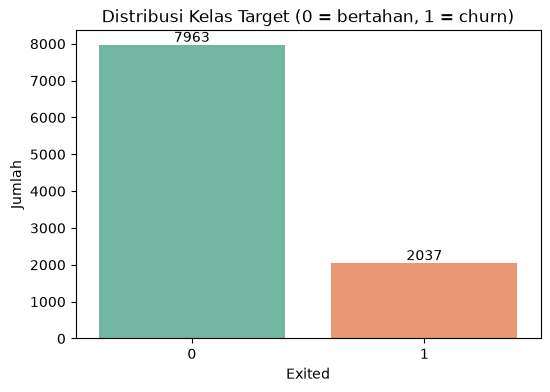

In [3]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.

counts = df[TARGET].value_counts().sort_index()
print("Proporsi kelas:")
display(df[TARGET].value_counts(normalize=True).round(4))

plt.figure(figsize=(6, 4))
ax = sns.countplot(x=TARGET, hue=TARGET, data=df, palette="Set2", legend=False)
for i, v in enumerate(counts):
    ax.text(i, v, str(v), ha="center", va="bottom")
plt.title("Distribusi Kelas Target (0 = bertahan, 1 = churn)")
plt.ylabel("Jumlah")
plt.show()

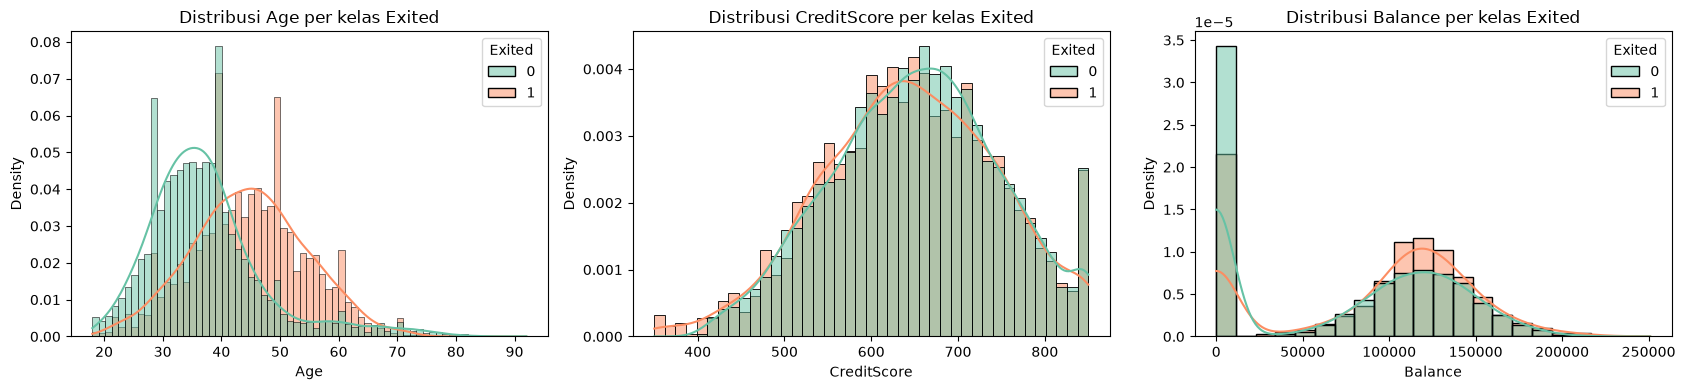

In [4]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, ["Age", "CreditScore", "Balance"]):
    # common_norm=False: tiap kelas dinormalisasi sendiri agar bentuk distribusinya bisa dibandingkan
    sns.histplot(data=df, x=col, hue=TARGET, kde=True, stat="density", common_norm=False, palette="Set2", ax=ax)
    ax.set_title(f"Distribusi {col} per kelas {TARGET}")
plt.tight_layout()
plt.show()

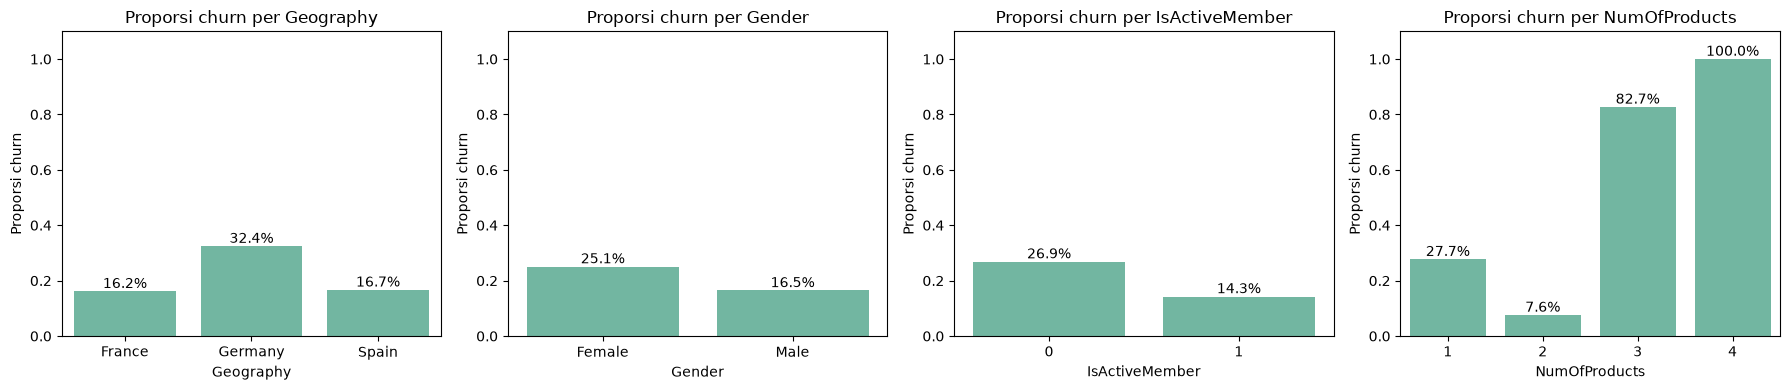

Jumlah nasabah per NumOfProducts:


NumOfProducts
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64

In [5]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).

cat_features = ["Geography", "Gender", "IsActiveMember", "NumOfProducts"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, cat_features):
    rate = df.groupby(col)[TARGET].mean()
    sns.barplot(x=rate.index.astype(str), y=rate.values, color="#66c2a5", ax=ax)
    for i, v in enumerate(rate.values):
        ax.text(i, v, f"{v:.1%}", ha="center", va="bottom")
    ax.set_title(f"Proporsi churn per {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Proporsi churn")
    ax.set_ylim(0, 1.1)
plt.tight_layout()
plt.show()

print("Jumlah nasabah per NumOfProducts:")
display(df["NumOfProducts"].value_counts().sort_index())

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

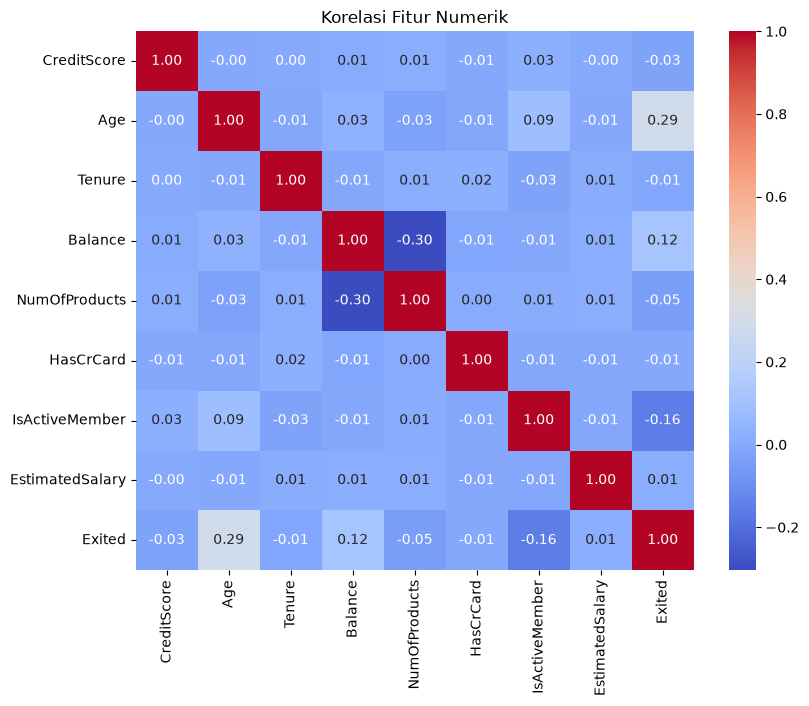

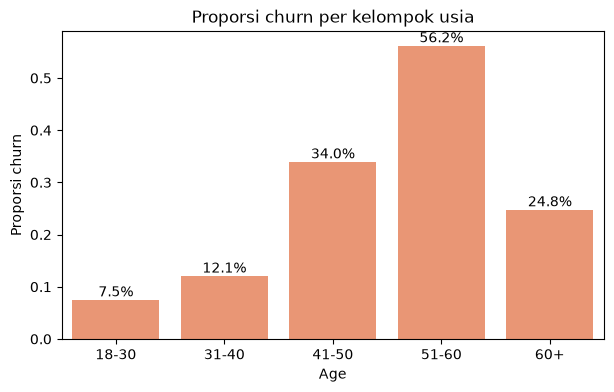

Proporsi nasabah dengan Balance = 0: 0.3617


Balance == 0
False    0.240796
True     0.138236
Name: Proporsi churn, dtype: float64

In [6]:
# Korelasi antar fitur numerik dan target
plt.figure(figsize=(9, 7))
sns.heatmap(df.drop(columns=["RowNumber", "CustomerId"]).corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Korelasi Fitur Numerik")
plt.show()

# Proporsi churn per kelompok usia
age_group = pd.cut(df["Age"], bins=[17, 30, 40, 50, 60, 100], labels=["18-30", "31-40", "41-50", "51-60", "60+"])
rate = df.groupby(age_group, observed=True)[TARGET].mean()
plt.figure(figsize=(7, 4))
ax = sns.barplot(x=rate.index.astype(str), y=rate.values, color="#fc8d62")
for i, v in enumerate(rate.values):
    ax.text(i, v, f"{v:.1%}", ha="center", va="bottom")
plt.title("Proporsi churn per kelompok usia")
plt.ylabel("Proporsi churn")
plt.show()

# Nasabah dengan saldo 0
print("Proporsi nasabah dengan Balance = 0:", round((df["Balance"] == 0).mean(), 4))
display(df.groupby(df["Balance"] == 0)[TARGET].mean().rename("Proporsi churn").rename_axis("Balance == 0"))

**Ringkasan hasil EDA:**

- Dataset berisi 10.000 baris dan 14 kolom tanpa missing value.
- Dataset **imbalanced**: 79,63% nasabah bertahan dan hanya 20,37% yang churn (perbandingan sekitar 4:1). Karena itu accuracy saja tidak cukup; model yang selalu menebak "bertahan" sudah mendapat accuracy sekitar 79,6%.
- **Age** adalah fitur numerik yang paling membedakan (korelasi 0,285 dengan `Exited`). Rata-rata usia nasabah churn 44,8 tahun, sedangkan yang bertahan 37,4 tahun. Hubungannya tidak linear: proporsi churn naik dari 7,5% (18-30) sampai 56,2% (51-60), lalu turun lagi menjadi 24,8% pada usia di atas 60.
- **CreditScore** hampir tidak membedakan kedua kelas (korelasi -0,027), distribusinya saling bertumpuk.
- **Balance**: 36,17% nasabah bersaldo 0, dan kelompok ini justru lebih jarang churn (13,8%) dibanding nasabah yang bersaldo (24,1%).
- **Geography**: nasabah Germany churn sekitar dua kali lebih sering (32,4%) dibanding France (16,2%) dan Spain (16,7%).
- **Gender**: perempuan (25,1%) lebih sering churn dibanding laki-laki (16,5%).
- **IsActiveMember**: nasabah tidak aktif (26,9%) churn hampir dua kali lebih sering dibanding yang aktif (14,3%).
- **NumOfProducts** juga tidak linear: 27,7% untuk 1 produk, hanya 7,6% untuk 2 produk, lalu melonjak ke 82,7% (3 produk) dan 100% (4 produk). Namun nasabah dengan 3-4 produk jumlahnya sedikit (266 dan 60 orang).

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [7]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.

# RowNumber  : hanya nomor urut baris, tidak membawa informasi tentang nasabah.
# CustomerId : ID unik acak per nasabah, tidak punya hubungan dengan perilaku churn.
# Surname    : nama keluarga, kardinalitas sangat tinggi dan tidak relevan; jika dipakai model hanya menghafal.
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
print("Kolom tersisa:", df.columns.tolist())

Kolom tersisa: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [8]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.

X = df.drop(columns=[TARGET])
y = df[TARGET]

# 70% train, lalu 30% sisanya dibagi dua sama besar: 15% validation dan 15% test
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

for name, ys in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name:<10} : {len(ys):>5} baris, proporsi churn = {ys.mean():.4f}")

Train      :  7000 baris, proporsi churn = 0.2037
Validation :  1500 baris, proporsi churn = 0.2040
Test       :  1500 baris, proporsi churn = 0.2033


In [9]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.

nominal_cols = ["Geography"]
binary_cols = ["Gender"]
numeric_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
# HasCrCard dan IsActiveMember sudah bernilai 0/1 sehingga dilewatkan apa adanya (passthrough)

preprocessor = ColumnTransformer([
    ("nominal", OneHotEncoder(handle_unknown="ignore"), nominal_cols),
    ("binary", OneHotEncoder(drop="if_binary"), binary_cols),
    ("numeric", StandardScaler(), numeric_cols),
], remainder="passthrough")

X_train_p = preprocessor.fit_transform(X_train)  # fit hanya pada train set
X_val_p = preprocessor.transform(X_val)
X_test_p = preprocessor.transform(X_test)

print("Fitur setelah preprocessing:", preprocessor.get_feature_names_out().tolist())
print("Bentuk X train/val/test:", X_train_p.shape, X_val_p.shape, X_test_p.shape)

Fitur setelah preprocessing: ['nominal__Geography_France', 'nominal__Geography_Germany', 'nominal__Geography_Spain', 'binary__Gender_Male', 'numeric__CreditScore', 'numeric__Age', 'numeric__Tenure', 'numeric__Balance', 'numeric__NumOfProducts', 'numeric__EstimatedSalary', 'remainder__HasCrCard', 'remainder__IsActiveMember']
Bentuk X train/val/test: (7000, 12) (1500, 12) (1500, 12)


In [10]:
# Ubah X dan y untuk train, validation, dan test menjadi tensor bertipe float32.
# Bentuk y diubah menjadi (N, 1) agar sesuai dengan output model, contoh: torch.tensor(y, dtype=torch.float32).view(-1, 1)
# Buat DataLoader untuk train set (shuffle=True) menggunakan TensorDataset.

def to_tensor(X, y):
    return (torch.tensor(X, dtype=torch.float32),
            torch.tensor(y.values, dtype=torch.float32).view(-1, 1))

X_train_t, y_train_t = to_tensor(X_train_p, y_train)
X_val_t, y_val_t = to_tensor(X_val_p, y_val)
X_test_t, y_test_t = to_tensor(X_test_p, y_test)

BATCH_SIZE = 64
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=BATCH_SIZE, shuffle=True)

print("X_train:", X_train_t.shape, X_train_t.dtype, "| y_train:", y_train_t.shape, y_train_t.dtype)
print("Jumlah batch per epoch:", len(train_loader))

X_train: torch.Size([7000, 12]) torch.float32 | y_train: torch.Size([7000, 1]) torch.float32
Jumlah batch per epoch: 110


# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [11]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

logreg = LogisticRegression(max_iter=1000, random_state=SEED)
logreg.fit(X_train_p, y_train)

# Hasil prediksi semua model dikumpulkan di sini: nama -> (label, probabilitas kelas 1)
results = {"Logistic Regression": (logreg.predict(X_test_p), logreg.predict_proba(X_test_p)[:, 1])}
print("Accuracy test Logistic Regression:", round(accuracy_score(y_test, results["Logistic Regression"][0]), 4))

Accuracy test Logistic Regression: 0.8153


## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer** dan **1 neuron output**. Di PyTorch, output layer cukup berupa `nn.Linear` tanpa Sigmoid, lalu gunakan **`nn.BCEWithLogitsLoss`** sebagai loss function. Loss ini sudah menggabungkan Sigmoid dan Binary Cross-Entropy sehingga lebih stabil secara numerik.

Contoh arsitektur: `Input → Linear(16) → ReLU → Linear(1)`

In [12]:
# Definisikan arsitektur ANN sederhana sebagai class turunan nn.Module (gunakan nn.Sequential, nn.Linear, dan nn.ReLU).
# Tampilkan arsitektur model dengan print(model) dan hitung jumlah parameternya: sum(p.numel() for p in model.parameters()).

N_FEATURES = X_train_t.shape[1]

class SimpleANN(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 16),
            nn.ReLU(),
            nn.Linear(16, 1),  # output berupa logit, tanpa Sigmoid
        )

    def forward(self, x):
        return self.net(x)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

torch.manual_seed(SEED)
model_simple = SimpleANN(N_FEATURES)
print(model_simple)
print("Jumlah parameter:", count_params(model_simple))

SimpleANN(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter: 225


In [13]:
# Tentukan loss function (nn.BCEWithLogitsLoss), optimizer (misalnya torch.optim.Adam), learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Untuk setiap batch: forward -> hitung loss -> optimizer.zero_grad() -> loss.backward() -> optimizer.step().
# Di akhir setiap epoch, hitung loss dan accuracy pada train set dan validation set (gunakan model.eval() dan torch.no_grad()),
# lalu simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.3 dan 3.4.

LR = 1e-3
EPOCHS = 100

def evaluate(model, X, y, criterion):
    """Loss dan accuracy pada satu set penuh."""
    model.eval()
    with torch.no_grad():
        logits = model(X)
        loss = criterion(logits, y).item()
        acc = ((torch.sigmoid(logits) >= 0.5).float() == y).float().mean().item()
    return loss, acc

def train_model(model, criterion, epochs=EPOCHS, lr=LR):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in train_loader:
            loss = criterion(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        train_loss, train_acc = evaluate(model, X_train_t, y_train_t, criterion)
        val_loss, val_acc = evaluate(model, X_val_t, y_val_t, criterion)
        for key, value in zip(history, [train_loss, train_acc, val_loss, val_acc]):
            history[key].append(value)
        if epoch % 10 == 0 or epoch == 1:
            print(f"Epoch {epoch:>3}/{epochs} | train loss {train_loss:.4f} acc {train_acc:.4f} | "
                  f"val loss {val_loss:.4f} acc {val_acc:.4f}")
    return history

histories = {}
histories["ANN Sederhana"] = train_model(model_simple, nn.BCEWithLogitsLoss())

Epoch   1/100 | train loss 0.4874 acc 0.7963 | val loss 0.4864 acc 0.7960


Epoch  10/100 | train loss 0.3638 acc 0.8476 | val loss 0.3492 acc 0.8487


Epoch  20/100 | train loss 0.3480 acc 0.8540 | val loss 0.3328 acc 0.8607


Epoch  30/100 | train loss 0.3431 acc 0.8580 | val loss 0.3291 acc 0.8607


Epoch  40/100 | train loss 0.3405 acc 0.8577 | val loss 0.3281 acc 0.8640


Epoch  50/100 | train loss 0.3389 acc 0.8583 | val loss 0.3273 acc 0.8653


Epoch  60/100 | train loss 0.3372 acc 0.8616 | val loss 0.3265 acc 0.8633


Epoch  70/100 | train loss 0.3359 acc 0.8609 | val loss 0.3264 acc 0.8660


Epoch  80/100 | train loss 0.3348 acc 0.8613 | val loss 0.3258 acc 0.8667


Epoch  90/100 | train loss 0.3338 acc 0.8616 | val loss 0.3248 acc 0.8673


Epoch 100/100 | train loss 0.3329 acc 0.8621 | val loss 0.3244 acc 0.8687


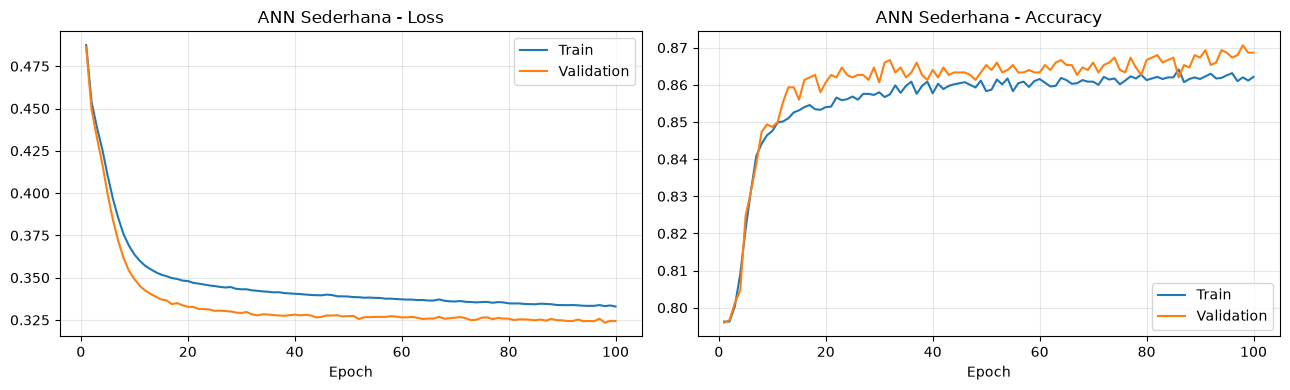

In [14]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot menggunakan dictionary history.

def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, metric in zip(axes, ["loss", "acc"]):
        ax.plot(epochs, history[f"train_{metric}"], label="Train")
        ax.plot(epochs, history[f"val_{metric}"], label="Validation")
        ax.set_title(f"{title} - {'Loss' if metric == 'loss' else 'Accuracy'}")
        ax.set_xlabel("Epoch")
        ax.legend()
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_history(histories["ANN Sederhana"], "ANN Sederhana")

In [15]:
# Lakukan prediksi pada test set. Gunakan model.eval() dan torch.no_grad().
# Output model berupa logit, ubah menjadi probabilitas dengan torch.sigmoid(), lalu menjadi label dengan threshold 0.5.
# Simpan probabilitas dan label dalam bentuk numpy array untuk keperluan evaluasi.

def predict(model, X, threshold=0.5):
    model.eval()
    with torch.no_grad():
        proba = torch.sigmoid(model(X)).numpy().ravel()
    return (proba >= threshold).astype(int), proba

results["ANN Sederhana"] = predict(model_simple, X_test_t)
print("Accuracy test ANN Sederhana:", round(accuracy_score(y_test, results["ANN Sederhana"][0]), 4))

Accuracy test ANN Sederhana: 0.864


## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [16]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan nn.Dropout(p) di antara hidden layer.
# Ingat: Dropout hanya aktif saat model.train() dan otomatis nonaktif saat model.eval().
# Tampilkan arsitektur model beserta jumlah parameternya.

class DeepANN(nn.Module):
    def __init__(self, n_features, p=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 64), nn.ReLU(), nn.Dropout(p),
            nn.Linear(64, 32), nn.ReLU(), nn.Dropout(p),
            nn.Linear(32, 16), nn.ReLU(),
            nn.Linear(16, 1),
        )

    def forward(self, x):
        return self.net(x)

torch.manual_seed(SEED)
model_deep = DeepANN(N_FEATURES)
print(model_deep)
print("Jumlah parameter:", count_params(model_deep))

DeepANN(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=16, bias=True)
    (7): ReLU()
    (8): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter: 3457


Epoch   1/100 | train loss 0.4534 acc 0.7963 | val loss 0.4486 acc 0.7960


Epoch  10/100 | train loss 0.3475 acc 0.8571 | val loss 0.3345 acc 0.8527


Epoch  20/100 | train loss 0.3375 acc 0.8636 | val loss 0.3331 acc 0.8627


Epoch  30/100 | train loss 0.3271 acc 0.8667 | val loss 0.3222 acc 0.8693


Epoch  40/100 | train loss 0.3221 acc 0.8696 | val loss 0.3227 acc 0.8667


Epoch  50/100 | train loss 0.3188 acc 0.8714 | val loss 0.3246 acc 0.8653


Epoch  60/100 | train loss 0.3130 acc 0.8729 | val loss 0.3222 acc 0.8673


Epoch  70/100 | train loss 0.3105 acc 0.8741 | val loss 0.3257 acc 0.8627


Epoch  80/100 | train loss 0.3090 acc 0.8757 | val loss 0.3268 acc 0.8613


Epoch  90/100 | train loss 0.3039 acc 0.8771 | val loss 0.3276 acc 0.8653


Epoch 100/100 | train loss 0.3006 acc 0.8769 | val loss 0.3301 acc 0.8620


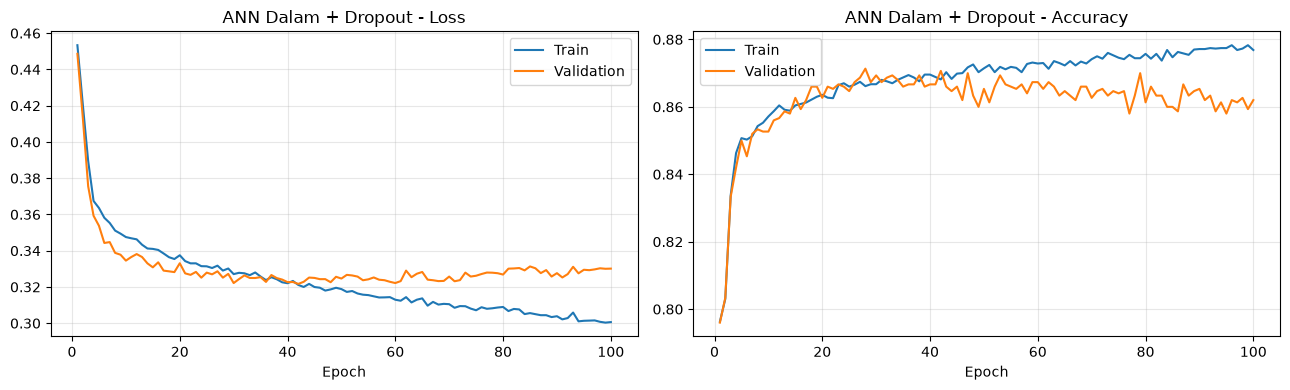

ANN Sederhana        | loss train 0.3329 val 0.3244 (selisih -0.0085) | val loss terendah di epoch 98
ANN Dalam + Dropout  | loss train 0.3006 val 0.3301 (selisih +0.0295) | val loss terendah di epoch 42


In [17]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?

histories["ANN Dalam + Dropout"] = train_model(model_deep, nn.BCEWithLogitsLoss())
plot_history(histories["ANN Dalam + Dropout"], "ANN Dalam + Dropout")

# Selisih train vs validation di epoch terakhir sebagai indikator overfitting
for name, h in histories.items():
    print(f"{name:<20} | loss train {h['train_loss'][-1]:.4f} val {h['val_loss'][-1]:.4f} "
          f"(selisih {h['val_loss'][-1] - h['train_loss'][-1]:+.4f}) | val loss terendah di epoch {int(np.argmin(h['val_loss'])) + 1}")

**Perbandingan learning curve 3.2 dan 3.3:**

- **ANN Sederhana (3.2):** train loss dan validation loss turun bersama dan masih turun sedikit sampai epoch 100 (train 0,3329, validation 0,3244; validation loss terendah di epoch 98). Tidak ada tanda overfitting, kedua kurva berhimpit.
- **ANN Dalam + Dropout (3.3):** train loss terus turun sampai 0,3006, tetapi validation loss mencapai titik terendah di epoch 42 lalu naik perlahan sampai 0,3301. Validation accuracy juga turun dari sekitar 0,869 (epoch 30) menjadi 0,862 (epoch 100), sementara train accuracy terus naik sampai 0,877. Ini tanda **overfitting ringan** setelah sekitar epoch 40, walaupun sudah memakai Dropout 0,3. Selisih loss train-validation di akhir adalah +0,0295, sedangkan pada model 3.2 justru -0,0085.

In [18]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.

results["ANN Dalam + Dropout"] = predict(model_deep, X_test_t)
print("Accuracy test ANN Dalam + Dropout:", round(accuracy_score(y_test, results["ANN Dalam + Dropout"][0]), 4))

Accuracy test ANN Dalam + Dropout: 0.8627


## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [19]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung pos_weight = jumlah kelas 0 / jumlah kelas 1 pada train set.
# Masukkan ke loss function: nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight])).

# Arsitektur terbaik dipilih dari validation loss epoch terakhir (bukan dari test set)
best_name = min(["ANN Sederhana", "ANN Dalam + Dropout"], key=lambda n: histories[n]["val_loss"][-1])
BestArch = {"ANN Sederhana": SimpleANN, "ANN Dalam + Dropout": DeepANN}[best_name]
print("Arsitektur terbaik:", best_name)

n_neg, n_pos = (y_train == 0).sum(), (y_train == 1).sum()
pos_weight = n_neg / n_pos
print(f"Kelas 0 = {n_neg}, kelas 1 = {n_pos}, pos_weight = {pos_weight:.4f}")

torch.manual_seed(SEED)
model_weighted = BestArch(N_FEATURES)  # dibuat ulang agar bobot mulai dari awal
weighted_name = f"{best_name} + Class Weight"
histories[weighted_name] = train_model(
    model_weighted, nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight], dtype=torch.float32)))

Arsitektur terbaik: ANN Sederhana
Kelas 0 = 5574, kelas 1 = 1426, pos_weight = 3.9088


Epoch   1/100 | train loss 1.0494 acc 0.7403 | val loss 1.0482 acc 0.7487


Epoch  10/100 | train loss 0.7806 acc 0.7604 | val loss 0.7394 acc 0.7673


Epoch  20/100 | train loss 0.7464 acc 0.7876 | val loss 0.7031 acc 0.7847


Epoch  30/100 | train loss 0.7348 acc 0.7874 | val loss 0.6953 acc 0.7867


Epoch  40/100 | train loss 0.7289 acc 0.7853 | val loss 0.6936 acc 0.7767


... (2 outputs left out)

Epoch  70/100 | train loss 0.7204 acc 0.7916 | val loss 0.6872 acc 0.7887


Epoch  80/100 | train loss 0.7188 acc 0.7881 | val loss 0.6878 acc 0.7813


Epoch  90/100 | train loss 0.7176 acc 0.7847 | val loss 0.6876 acc 0.7820


Epoch 100/100 | train loss 0.7161 acc 0.7894 | val loss 0.6861 acc 0.7880


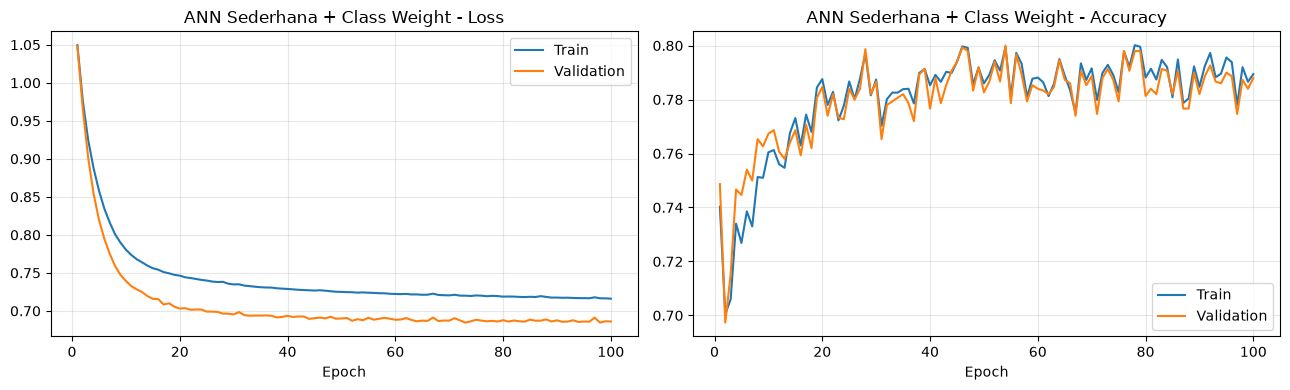

Accuracy test ANN Sederhana + Class Weight: 0.7847


In [20]:
# Tampilkan learning curve train vs validation.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

plot_history(histories[weighted_name], weighted_name)

results[weighted_name] = predict(model_weighted, X_test_t)
print(f"Accuracy test {weighted_name}:", round(accuracy_score(y_test, results[weighted_name][0]), 4))

# 4. Evaluasi Model

In [21]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

metrics = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
        "ROC AUC": roc_auc_score(y_test, proba),
    }
    for name, (pred, proba) in results.items()
]).set_index("Model")
display(metrics.round(4))

,Accuracy,Precision,Recall,F1-Score,ROC AUC
Model,,,,,
Logistic Regression,0.8153,0.6458,0.2033,0.3092,0.7913
ANN Sederhana,0.8640,0.7563,0.4885,0.5936,0.8645
ANN Dalam + Dropout,0.8627,0.7797,0.4525,0.5726,0.8640
ANN Sederhana + Class Weight,0.7847,0.4816,0.7738,0.5937,0.8695


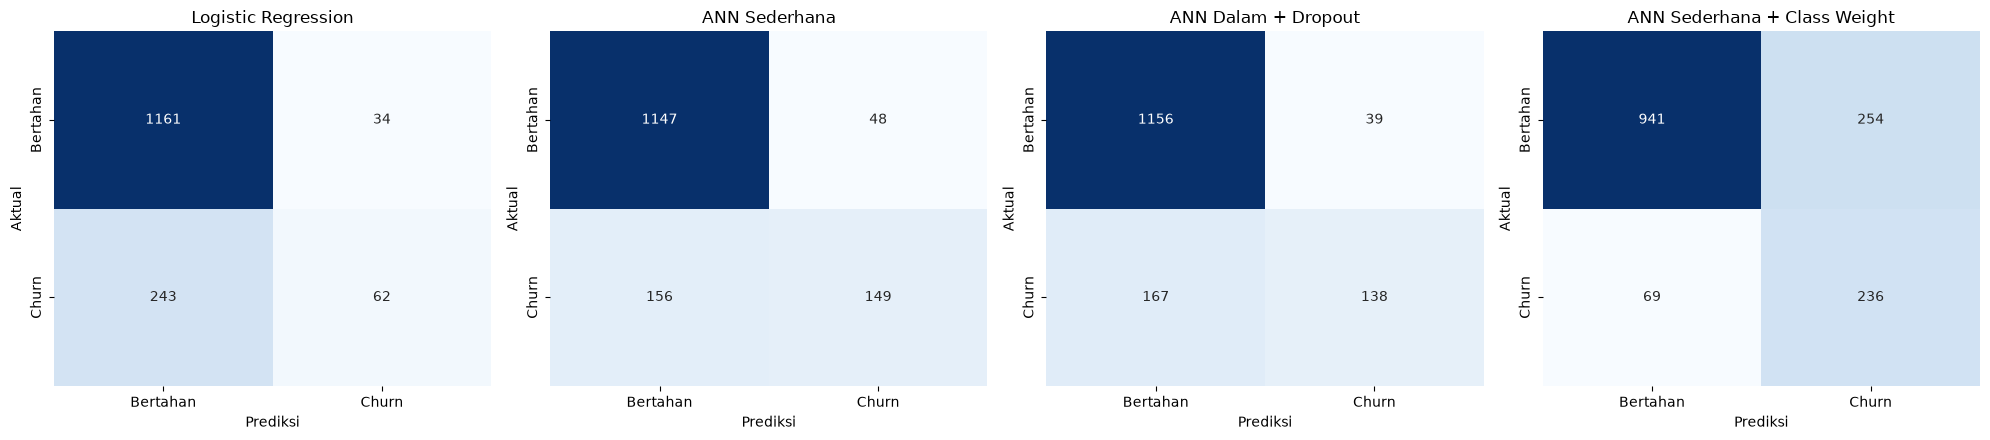

In [22]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.

fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 4.5))
for ax, (name, (pred, _)) in zip(axes, results.items()):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Bertahan", "Churn"], yticklabels=["Bertahan", "Churn"])
    ax.set_title(name)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
plt.tight_layout()
plt.show()

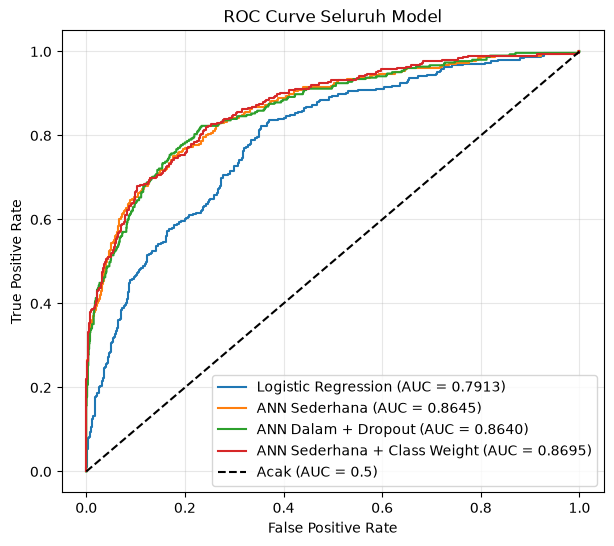

In [23]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.

plt.figure(figsize=(7, 6))
for name, (_, proba) in results.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Acak (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Seluruh Model")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa Logistic Regression dan setiap konfigurasi ANN berdasarkan hasil evaluasi. Bahas pula bentuk learning curve masing-masing model (overfitting/underfitting), pengaruh penambahan layer dan Dropout, serta pengaruh class weight terhadap precision dan recall kelas churn. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

**Ringkasan hasil pada test set (1.500 nasabah, 305 di antaranya churn):**

| Model | Accuracy | Precision | Recall | F1-Score | ROC AUC | Parameter |
|---|---|---|---|---|---|---|
| Logistic Regression | 0,8153 | 0,6458 | 0,2033 | 0,3092 | 0,7913 | 13 |
| ANN Sederhana | 0,8640 | 0,7563 | 0,4885 | 0,5936 | 0,8645 | 225 |
| ANN Dalam + Dropout | 0,8627 | 0,7797 | 0,4525 | 0,5726 | 0,8640 | 3.457 |
| ANN Sederhana + Class Weight | 0,7847 | 0,4816 | 0,7738 | 0,5937 | 0,8695 | 225 |

**1. Logistic Regression vs ANN**

Logistic Regression mendapat accuracy 0,8153, hanya sedikit di atas tebakan kelas mayoritas (0,7967 pada test set). Recall-nya sangat rendah, 0,2033: dari 305 nasabah churn hanya 62 yang terdeteksi dan 243 terlewat. ANN Sederhana dengan satu hidden layer berisi 16 neuron menaikkan accuracy menjadi 0,8640, recall menjadi 0,4885 (149 terdeteksi), F1 dari 0,3092 menjadi 0,5936, dan AUC dari 0,7913 menjadi 0,8645.

Penyebab yang paling masuk akal terlihat di EDA: hubungan `Age` dan `NumOfProducts` dengan churn tidak linear (churn tertinggi di usia 51-60 lalu turun, churn terendah pada 2 produk lalu melonjak pada 3-4 produk). Logistic Regression hanya bisa membuat batas keputusan linear pada fitur yang diberikan, sedangkan hidden layer dengan ReLU bisa membentuk hubungan seperti itu. Jadi pada dataset ini ANN memang layak dipakai dibanding baseline.

**2. Pengaruh penambahan layer dan Dropout**

ANN Dalam + Dropout punya parameter sekitar 15 kali lebih banyak (3.457 vs 225), tetapi hasilnya di test set tidak lebih baik: accuracy 0,8627 vs 0,8640, F1 0,5726 vs 0,5936, AUC 0,8640 vs 0,8645. Precision-nya sedikit lebih tinggi (0,7797 vs 0,7563) tetapi recall lebih rendah (0,4525 vs 0,4885). Selisih sekecil ini (beberapa nasabah saja di confusion matrix) belum bisa dianggap berbeda nyata karena hanya berasal dari satu kali training dengan satu seed.

Artinya untuk data tabular kecil dengan 12 fitur, satu hidden layer sudah cukup, dan kapasitas tambahan tidak menemukan pola baru.

**3. Learning curve (overfitting/underfitting)**

- **ANN Sederhana:** kurva train dan validation berhimpit sampai akhir (loss 0,3329 vs 0,3244) dan masih turun pelan. Tidak overfitting. Validation loss sedikit lebih rendah dari train loss, kemungkinan karena pembagian data yang kebetulan lebih mudah di validation set.
- **ANN Dalam + Dropout:** train loss turun terus sampai 0,3006, sedangkan validation loss terendah di epoch 42 lalu naik ke 0,3301. Ini overfitting ringan. Dropout 0,3 memperlambat overfitting tetapi tidak menghilangkannya pada 100 epoch. Jika training dihentikan di sekitar epoch 40 (early stopping), model ini kemungkinan setara atau sedikit lebih baik.
- **ANN Sederhana + Class Weight:** nilai loss-nya lebih besar (sekitar 0,72 dan 0,69) karena kesalahan pada kelas churn dikalikan 3,91, jadi tidak bisa dibandingkan langsung dengan loss model lain. Kurva train dan validation tetap berhimpit, tidak overfitting.
- Tidak ada model ANN yang underfitting dibanding baseline, karena semuanya jauh lebih baik dari Logistic Regression pada AUC.

**4. Pengaruh class weight terhadap precision dan recall kelas churn**

Dengan `pos_weight = 5574 / 1426 = 3,91`, recall kelas churn naik dari 0,4885 menjadi 0,7738 (236 dari 305 nasabah churn terdeteksi, yang terlewat turun dari 156 menjadi 69). Sebagai gantinya precision turun dari 0,7563 menjadi 0,4816: false positive naik dari 48 menjadi 254, sehingga accuracy turun dari 0,8640 menjadi 0,7847.

F1-Score hampir tidak berubah (0,5937 vs 0,5936) dan AUC juga hampir sama (0,8695 vs 0,8645). Jadi class weight **tidak membuat model lebih pandai memisahkan kedua kelas**, tetapi menggeser titik keputusan sehingga model lebih mudah memprediksi churn. Pilihan antara kedua model bergantung pada biaya kesalahan: jika kehilangan nasabah lebih mahal dibanding biaya menghubungi nasabah yang sebenarnya tidak akan churn, model dengan class weight lebih berguna walaupun accuracy-nya paling rendah.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

**Kesimpulan**

1. ANN lebih baik dari Logistic Regression pada dataset ini (AUC 0,86-0,87 vs 0,79; F1 sekitar 0,59 vs 0,31), kemungkinan besar karena hubungan `Age` dan `NumOfProducts` dengan churn tidak linear.
2. Menambah kedalaman (3 hidden layer + Dropout, 3.457 parameter) tidak memberi peningkatan dibanding 1 hidden layer (225 parameter), dan malah menunjukkan overfitting ringan setelah sekitar epoch 40.
3. Karena data imbalanced (20,37% churn), accuracy menyesatkan. Model tanpa class weight hanya menangkap kurang dari separuh nasabah churn (recall 0,45-0,49).
4. Class weight menaikkan recall churn menjadi 0,7738 dengan mengorbankan precision (0,4816) dan accuracy (0,7847), sementara F1 dan AUC hampir tidak berubah. Untuk tujuan mencegah churn, model **ANN Sederhana + Class Weight** adalah pilihan yang paling masuk akal.

**Saran**

- Memakai early stopping berdasarkan validation loss, terutama untuk model yang lebih dalam.
- Mencari threshold terbaik pada validation set (bukan tetap 0,5) sesuai biaya false positive dan false negative, sebagai alternatif atau pelengkap class weight.
- Mengulang training dengan beberapa seed atau cross-validation, karena selisih antar konfigurasi ANN di sini kecil dan hanya dari satu kali training.
- Mencoba metode penanganan imbalance lain (misalnya oversampling/SMOTE pada train set) dan membandingkannya dengan class weight.
- Membandingkan dengan model berbasis pohon (Random Forest, Gradient Boosting) yang biasanya kuat pada data tabular.
- Menambah fitur turunan, misalnya penanda `Balance == 0` atau kelompok usia, yang terlihat informatif pada EDA.